# Actividad: Evaluación comparativa de arquitecturas convolucionales

Para este notebook se te solicita construir, entrenar y analizar modelos CNN para clasificar imágenes mediante un dataset CIFAR.

**Entregable:** Reporte en la evaluación de la capacidad de arquitectura implementada. Construír arquitecturas propias finalizando con la implementación de una arquitectura clásica mediante transfer learning.


## Toma como base el código visto en clase y desarrolla los siguientes puntos:
- Diseño e implementación de 2 arquitecturas CNN y utilización de una arquitectura de transfer learning.

- Buen uso de data augmentation y regularización.

- Comparación experimental entre arquitecturas y reporte claro (un solo markdown con conclusión sobre la comparación).

## Alcance de la comparación

La comparación directa se realiza entre las dos CNN didácticas personalizadas, `vgg16` y `resnet50`, porque ambas se entrenan desde cero bajo el mismo protocolo. `mobilenet` se incluye como referencia adicional mediante *transfer learning*: MobileNetV2 utiliza pesos preentrenados de ImageNet, mantiene congelada su base convolucional y agrega una cabeza de clasificación para CIFAR-10.

Por lo tanto, MobileNetV2 no constituye una comparación estrictamente equivalente. Una diferencia de rendimiento puede reflejar el conocimiento transferido desde ImageNet y no únicamente la arquitectura. En el análisis se deben distinguir los parámetros totales, entrenables y no entrenables, así como el preentrenamiento, el tiempo de entrenamiento y las métricas obtenidas en prueba.





In [1]:
import numpy as np
import pandas as pd
import csv
import json
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50,VGG16,MobileNetV2# (seleccióna la arquitectura que desees, puedes buscar otras) VGG16, ResNet50, MobileNetV2
from pathlib import Path
from sklearn.model_selection import train_test_split

keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()


## Definiciones de modelos

In [2]:
def crear_augmentation():
    """Define transformaciones aleatorias aplicadas solo durante el entrenamiento."""
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomTranslation(0.08, 0.08)
    ])

# Funcion de data augmentation para aumentar la variabilidad de los datos de entrenamiento y evitar el sobreajuste del modelo.

#-------------------------------------------------------------------------------

def crear_cnn_secuencial():
    """Construye una CNN secuencial didactica con regularizacion L2 y dropout."""

    # CNN secuencial personalizada.

    entradas = keras.Input(shape=(64, 64, 3))

    x = crear_augmentation()(entradas)
    x = layers.Rescaling(1./255)(x)

    for filtros in [32, 64, 128]:
        x = layers.Conv2D(
            filtros, 3, padding="same",
            activation="relu"
        )(x)

        x = layers.Conv2D(
            filtros, 3, padding="same",
            activation="relu"
        )(x)

        x = layers.MaxPooling2D(pool_size=2)(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(1e-4)
    )(x)

    x = layers.Dropout(0.3)(x)

    salidas = layers.Dense(
        10, activation="softmax"
    )(x)

    return keras.Model(entradas, salidas)

#---------------------------------------------------------------------------------------

# CNN residual personalizada inspirada en ResNet.

def bloque_residual(x, filtros, stride=1):
    """Aplica dos convoluciones y suma una atajo proyectado si es necesario."""

    atajo = x

    # Primera convolución
    y = layers.Conv2D(
        filtros, 3, strides=stride,
        padding="same", use_bias=False
    )(x)
    y = layers.BatchNormalization()(y)
    y = layers.ReLU()(y)

    # Segunda convolución
    y = layers.Conv2D(
        filtros, 3,
        padding="same", use_bias=False
    )(y)
    y = layers.BatchNormalization()(y)

    # Proyección cuando cambian las dimensiones
    if stride != 1 or x.shape[-1] != filtros:
        atajo = layers.Conv2D(
            filtros, 1, strides=stride,
            padding="same", use_bias=False
        )(atajo)
        atajo = layers.BatchNormalization()(atajo)

    # Conexión residual
    y = layers.Add()([y, atajo])

    return layers.ReLU()(y)


def crear_cnn_residual():
    """Construye una CNN residual didactica sin modificar la arquitectura base."""

    entradas = keras.Input(shape=(64, 64, 3))

    x = crear_augmentation()(entradas)
    x = layers.Rescaling(1./255)(x)

    x = layers.Conv2D(
        32, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = bloque_residual(x, 32)
    x = bloque_residual(x, 64, stride=2)
    x = bloque_residual(x, 128, stride=2)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    salidas = layers.Dense(
        10, activation="softmax"
    )(x)

    return keras.Model(entradas, salidas)

#---------------------------------------------------------------------------------------

# MobileNetV2 con transfer learning.

def crear_mobilenet_transfer():
    """Construye MobileNetV2 congelada y agrega una cabeza para CIFAR-10."""

    base = keras.applications.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(64, 64, 3)
    )

    base.trainable = False

    entradas = keras.Input(shape=(64, 64, 3))

    x = crear_augmentation()(entradas)

    # Preprocesamiento esperado por MobileNetV2
    x = layers.Rescaling(
        scale=1./127.5,
        offset=-1
    )(x)

    x = base(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)

    salidas = layers.Dense(
        10, activation="softmax"
    )(x)

    return keras.Model(entradas, salidas)

In [3]:
cnn_1 = crear_cnn_secuencial()
cnn_2 = crear_cnn_residual()
cnn_3 = crear_mobilenet_transfer()

cnn_1.summary()
cnn_2.summary()
cnn_3.summary(expand_nested=True)



Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 64, 64, 3)]       0         
                                                                 
 sequential (Sequential)     (None, 64, 64, 3)         0         
                                                                 
 rescaling (Rescaling)       (None, 64, 64, 3)         0         
                                                                 
 conv2d (Conv2D)             (None, 64, 64, 32)        896       
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 64, 32)        9248      
                                                                 
 max_pooling2d (MaxPooling2  (None, 32, 32, 32)        0         
 D)                                                              
                                                           

## Entrenamiento de modelos.

In [4]:
# Funcion para preparar los datos de entrenamiento, validacion y prueba.
# Los modelos realizan su propio escalado/preprocesamiento dentro de la arquitectura.

def preparar_datos(
    imagenes,
    etiquetas,
    arquitectura,
    batch_size=32,
    entrenamiento=False
):
    """Crea un dataset tf.data con resize, etiquetas one-hot y batching comun."""

    # Las imagenes llegan en RGB con valores [0, 255].
    if arquitectura not in {"vgg16", "resnet50", "mobilenet"}:
        raise ValueError("Arquitectura no reconocida")

    dataset = tf.data.Dataset.from_tensor_slices(
        (imagenes, etiquetas)
    )

    if entrenamiento:
        dataset = dataset.shuffle(
            buffer_size=10000,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(batch_size)

    def transformar(x, y):
        # Redimensionar CIFAR-10 de 32x32 a 64x64.
        x = tf.image.resize(
            tf.cast(x, tf.float32),
            [64, 64]
        )

        # Cada modelo aplica su escalado dentro de la arquitectura:
        # Rescaling(1./255) o Rescaling(1./127.5, offset=-1).
        y = tf.cast(tf.reshape(y, [-1]), tf.int32)
        # Convertir cada etiqueta entera (0-9) en un vector de 10 posiciones.
        # Esto es compatible con categorical_crossentropy y softmax.
        y = tf.one_hot(y, depth=10)
        return x, y

    dataset = dataset.map(
        transformar,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.prefetch(tf.data.AUTOTUNE)


In [6]:
"""
Entrenamiento reproducible de una arquitectura CNN seleccionada.

Ejecutar esta celda una vez por arquitectura que se necesite entrenar. Los
hiperparametros y la particion se mantienen constantes para la comparacion.
"""

# Protocolo comun de comparacion.
SEED = 42

# Cargar CIFAR-10.
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Separar 5,000 ejemplos de validacion conservando la proporcion de las 10 clases.
x_fit, x_val, y_fit, y_val = train_test_split(
    x_train,
    y_train,
    test_size=5000,
    random_state=SEED,
    stratify=y_train.reshape(-1)
)

ARQUITECTURA = "mobilenet"  # Usar tambien "resnet50" o "mobilenet".
LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 15

# Directorios destinados a los artefactos generados por los experimentos.
ARTEFACTOS_DIR = Path("artefactos")
MODELOS_DIR = ARTEFACTOS_DIR / "modelos"
HISTORIALES_DIR = ARTEFACTOS_DIR / "historiales"
CONFIGURACIONES_DIR = ARTEFACTOS_DIR / "configuraciones"
COMPARACIONES_DIR = ARTEFACTOS_DIR / "comparaciones"

for directorio in (
    MODELOS_DIR,
    HISTORIALES_DIR,
    CONFIGURACIONES_DIR,
    COMPARACIONES_DIR
):
    directorio.mkdir(parents=True, exist_ok=True)

creadores = {
    "vgg16": crear_cnn_secuencial,
    "resnet50": crear_cnn_residual,
    "mobilenet": crear_mobilenet_transfer
}

# Restablecer explicitamente el estado aleatorio antes de crear cada experimento.
# Esto hace comparable la inicializacion de las CNN entrenadas desde cero;
# MobileNetV2 sigue siendo una referencia de transfer learning no equivalente.
keras.utils.set_random_seed(SEED)
modelo = creadores[ARQUITECTURA]()

train_ds = preparar_datos(
    x_fit, y_fit,
    ARQUITECTURA,
    batch_size=BATCH_SIZE,
    entrenamiento=True
)

val_ds = preparar_datos(
    x_val, y_val,
    ARQUITECTURA,
    batch_size=BATCH_SIZE
)

test_ds = preparar_datos(
    x_test, y_test,
    ARQUITECTURA,
    batch_size=BATCH_SIZE
)

modelo.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODELOS_DIR / f"{ARQUITECTURA}_mejor.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.CSVLogger(
        str(HISTORIALES_DIR / f"{ARQUITECTURA}_historial.csv")
    )
]

historia = modelo.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Guardar tambien el modelo con los mejores pesos restaurados.
modelo.save(str(MODELOS_DIR / f"{ARQUITECTURA}_cifar10.keras"))

# Persistir la configuracion para reproducir y auditar la ejecucion.
configuracion = {
    "arquitectura": ARQUITECTURA,
    "seed": SEED,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "epochs_maximas": EPOCHS,
    "validation_size": 5000,
    "split": "estratificado",
    "input_shape": [64, 64, 3],
    "num_classes": 10,
    "preprocesamiento": "escalado interno de la arquitectura"
}
with open(CONFIGURACIONES_DIR / f"{ARQUITECTURA}_configuracion.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, indent=2)


Epoch 1/15
1407/1407 [==============================] - 47s 32ms/step - loss: 1.2047 - accuracy: 0.5790 - val_loss: 0.8940 - val_accuracy: 0.6932
Epoch 2/15
1407/1407 [==============================] - 44s 31ms/step - loss: 1.0520 - accuracy: 0.6310 - val_loss: 0.8583 - val_accuracy: 0.7086
Epoch 3/15
1407/1407 [==============================] - 44s 31ms/step - loss: 1.0125 - accuracy: 0.6422 - val_loss: 0.8347 - val_accuracy: 0.7146
Epoch 4/15
1407/1407 [==============================] - 45s 32ms/step - loss: 0.9848 - accuracy: 0.6535 - val_loss: 0.8294 - val_accuracy: 0.7160
Epoch 5/15
1407/1407 [==============================] - 44s 31ms/step - loss: 0.9687 - accuracy: 0.6581 - val_loss: 0.8333 - val_accuracy: 0.7138
Epoch 6/15
1407/1407 [==============================] - 44s 32ms/step - loss: 0.9599 - accuracy: 0.6622 - val_loss: 0.8085 - val_accuracy: 0.7218
Epoch 7/15
1407/1407 [==============================] - 44s 32ms/step - loss: 0.9411 - accuracy: 0.6655 - val_loss: 0.8076 -

In [6]:


ruta = Path("artefactos") / "modelos" / "resnet50_cifar10.keras"
if ruta.exists():
    modelo_cargado_resnet = keras.models.load_model(ruta)
    print("Modelo cargado:", ruta)
    print("Entrada:", modelo_cargado_resnet.input_shape)
    print("Salida:", modelo_cargado_resnet.output_shape)
    print("Parametros:", modelo_cargado_resnet.count_params())
else:
        print(f"Aun no existe: {ruta}. Ejecuta primero el entrenamiento de esta arquitectura.")


Modelo cargado: artefactos\modelos\resnet50_cifar10.keras
Entrada: (None, 64, 64, 3)
Salida: (None, 10)
Parametros: 309994


In [7]:


ruta = Path("artefactos") / "modelos" / "vgg16_cifar10.keras"
if ruta.exists():
    modelo_cargado_vgg = keras.models.load_model(ruta)
    print("Modelo cargado:", ruta)
    print("Entrada:", modelo_cargado_vgg.input_shape)
    print("Salida:", modelo_cargado_vgg.output_shape)
    print("Parametros:", modelo_cargado_vgg.count_params())
else:
        print(f"Aun no existe: {ruta}. Ejecuta primero el entrenamiento de esta arquitectura.")


Modelo cargado: artefactos\modelos\vgg16_cifar10.keras
Entrada: (None, 64, 64, 3)
Salida: (None, 10)
Parametros: 304810


In [7]:


ruta = Path("artefactos") / "modelos" / "mobilenet_cifar10.keras"
if ruta.exists():
    modelo_cargado_mobilenet = keras.models.load_model(ruta)
    print("Modelo cargado:", ruta)
    print("Entrada:", modelo_cargado_mobilenet.input_shape)
    print("Salida:", modelo_cargado_mobilenet.output_shape)
    print("Parametros:", modelo_cargado_mobilenet.count_params())
else:
        print(f"Aun no existe: {ruta}. Ejecuta primero el entrenamiento de esta arquitectura.")


Modelo cargado: artefactos\modelos\mobilenet_cifar10.keras
Entrada: (None, 64, 64, 3)
Salida: (None, 10)
Parametros: 2340618


## Comparación y gráficos de los distintos modelos.

In [5]:
"""
Comparación de arquitecturas del modelo final en datos de prueba.
"""


nombres = [
    "vgg16",
    "resnet50",
    "mobilenet"
]

if "x_test" not in globals():
    (_, _), (x_test, y_test) = keras.datasets.cifar10.load_data()
if "BATCH_SIZE" not in globals():
    BATCH_SIZE = 32

resultados_finales = []

for nombre in nombres:
    ruta = Path("artefactos") / "modelos" / f"{nombre}_cifar10.keras"

    if not ruta.exists():
        print(f"No se encontro: {ruta}")
        continue

    modelo = keras.models.load_model(ruta)
    test_ds = preparar_datos(
        x_test,
        y_test,
        nombre,
        batch_size=BATCH_SIZE
    )

    loss, accuracy = modelo.evaluate(
        test_ds,
        verbose=0
    )

    resultados_finales.append({
        "modelo": nombre,
        "test_loss": float(loss),
        "test_accuracy": float(accuracy),
        "parametros": int(modelo.count_params())
    })

if resultados_finales:
    with open(Path("artefactos") / "comparaciones" / "comparacion.csv", "w", newline="") as archivo:
        writer = csv.DictWriter(
            archivo,
            fieldnames=resultados_finales[0].keys()
        )
        writer.writeheader()
        writer.writerows(resultados_finales)

    with open(Path("artefactos") / "comparaciones" / "comparacion.json", "w", encoding="utf-8") as archivo:
        json.dump(resultados_finales, archivo, indent=2)

for resultado in resultados_finales:
    print(resultado)




{'modelo': 'vgg16', 'test_loss': 0.7304645776748657, 'test_accuracy': 0.7548999786376953, 'parametros': 304810}
{'modelo': 'resnet50', 'test_loss': 1.077770709991455, 'test_accuracy': 0.6140000224113464, 'parametros': 309994}
{'modelo': 'mobilenet', 'test_loss': 0.798471212387085, 'test_accuracy': 0.7236999869346619, 'parametros': 2340618}


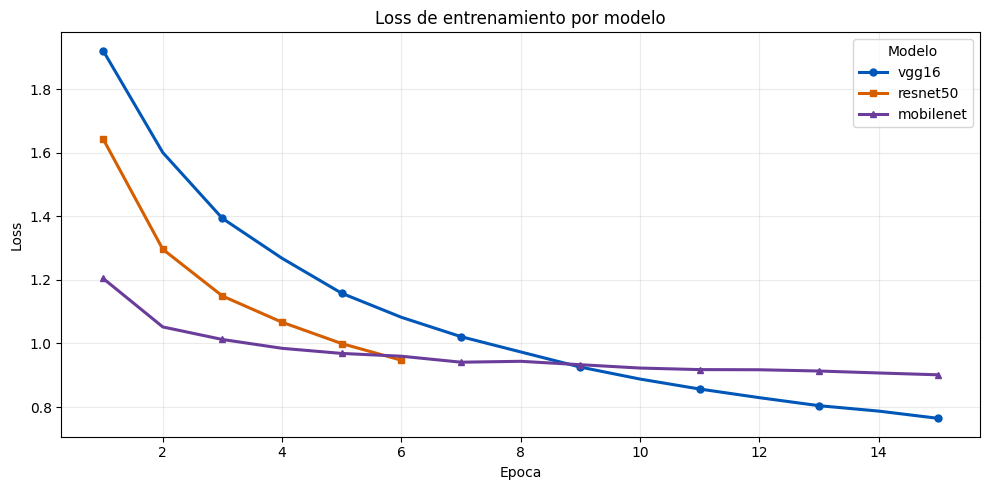

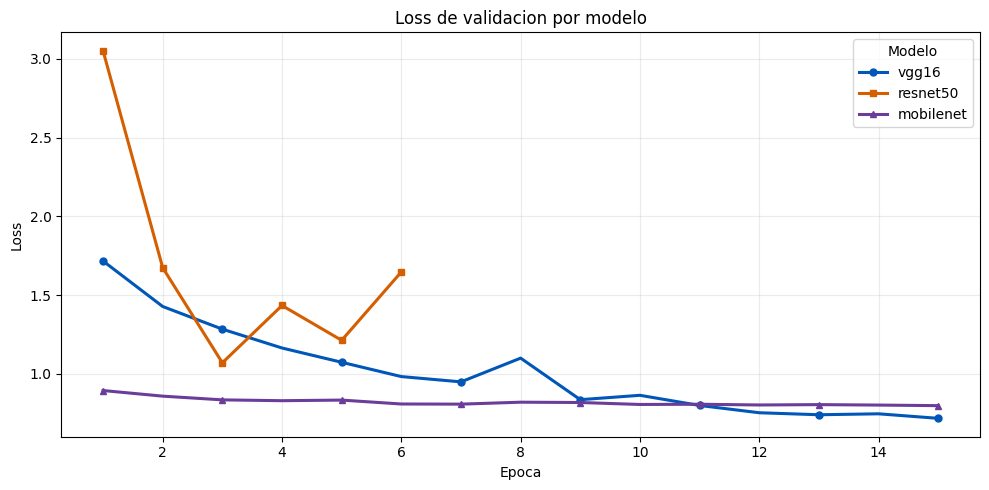

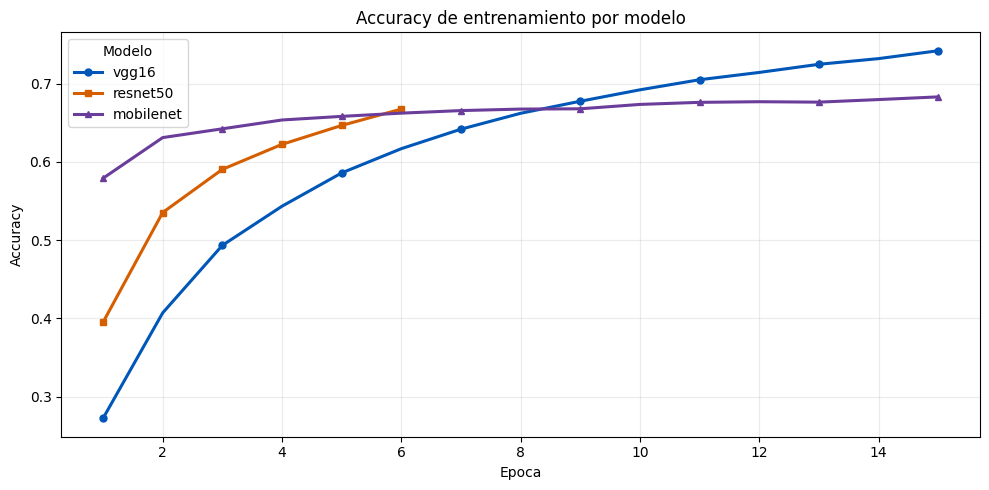

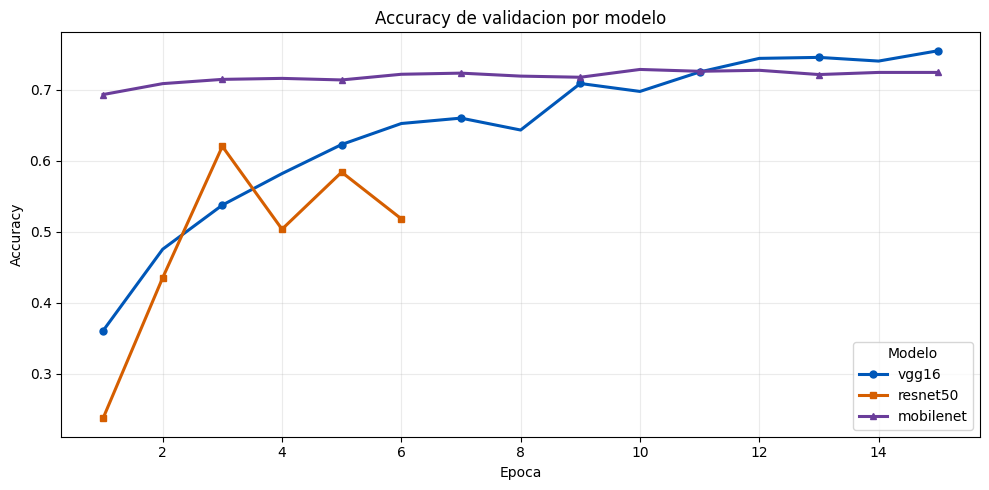

In [ ]:
"""
Comparacion de arquitecturas en datos de entrenamiento y validacion en cada epoca.
"""

arquitecturas = ["vgg16", "resnet50", "mobilenet"]
historiales = {}

for arquitectura in arquitecturas:
    historial_path = Path("artefactos") / "historiales" / f"{arquitectura}_historial.csv"
    if historial_path.exists():
        historiales[arquitectura] = pd.read_csv(historial_path)
    else:
        print(f"Falta el historial de {arquitectura}; ejecuta primero su entrenamiento.")

if not historiales:
    print("No hay historiales disponibles para comparar.")
else:
    colores = {"vgg16": "#0057B8", "resnet50": "#D55E00", "mobilenet": "#6A3D9A"}
    marcadores = {"vgg16": "o", "resnet50": "s", "mobilenet": "^"}

    def graficar_historial(metrica, conjunto, titulo):
        figura, eje = plt.subplots(figsize=(10, 5))
        columna = metrica if conjunto == "entrenamiento" else f"val_{metrica}"

        for arquitectura, historial_df in historiales.items():
            if "epoch" in historial_df.columns:
                epocas = historial_df["epoch"].to_numpy() + 1
            else:
                epocas = np.arange(1, len(historial_df) + 1)

            if columna in historial_df.columns:
                eje.plot(
                    epocas,
                    historial_df[columna],
                    color=colores[arquitectura],
                    marker=marcadores[arquitectura],
                    markevery=max(1, len(epocas) // 6),
                    markersize=5,
                    linewidth=2.2,
                    label=arquitectura
                )

        eje.set_title(titulo)
        eje.set_xlabel("Epoca")
        eje.set_ylabel(metrica.capitalize())
        eje.legend(title="Modelo")
        eje.grid(alpha=0.25)
        figura.tight_layout()
        plt.show()

    for metrica in ("loss", "accuracy"):
        graficar_historial(
            metrica,
            "entrenamiento",
            f"{metrica.capitalize()} de entrenamiento por modelo"
        )
        graficar_historial(
            metrica,
            "validacion",
            f"{metrica.capitalize()} de validacion por modelo"
        )

In [ ]:
"""

Comparación de arquitecturas del modelo final en datos de entrenamiento, validación y prueba.

"""


comparacion_path = Path("artefactos") / "comparaciones" / "comparacion.csv"
metricas_finales = []

if comparacion_path.exists():
    comparacion_prueba = pd.read_csv(comparacion_path)

    for arquitectura in ["vgg16", "resnet50", "mobilenet"]:
        historial_path = Path("artefactos") / "historiales" / f"{arquitectura}_historial.csv"
        resultado_prueba = comparacion_prueba[
            comparacion_prueba["modelo"] == arquitectura
        ]

        if historial_path.exists() and not resultado_prueba.empty:
            historial_df = pd.read_csv(historial_path)
            metricas_finales.append({
                "modelo": arquitectura,
                "entrenamiento": float(historial_df["accuracy"].iloc[-1]),
                "validacion": float(historial_df["val_accuracy"].iloc[-1]),
                "prueba": float(resultado_prueba["test_accuracy"].iloc[0])
            })

if metricas_finales:
    resumen = pd.DataFrame(metricas_finales)
    display(resumen)
else:
    print("Faltan historiales o resultados de prueba.")

,modelo,entrenamiento,validacion,prueba
0,vgg16,0.741956,0.7550,0.7549
1,resnet50,0.667378,0.5180,0.6140
2,mobilenet,0.682978,0.7244,0.7237


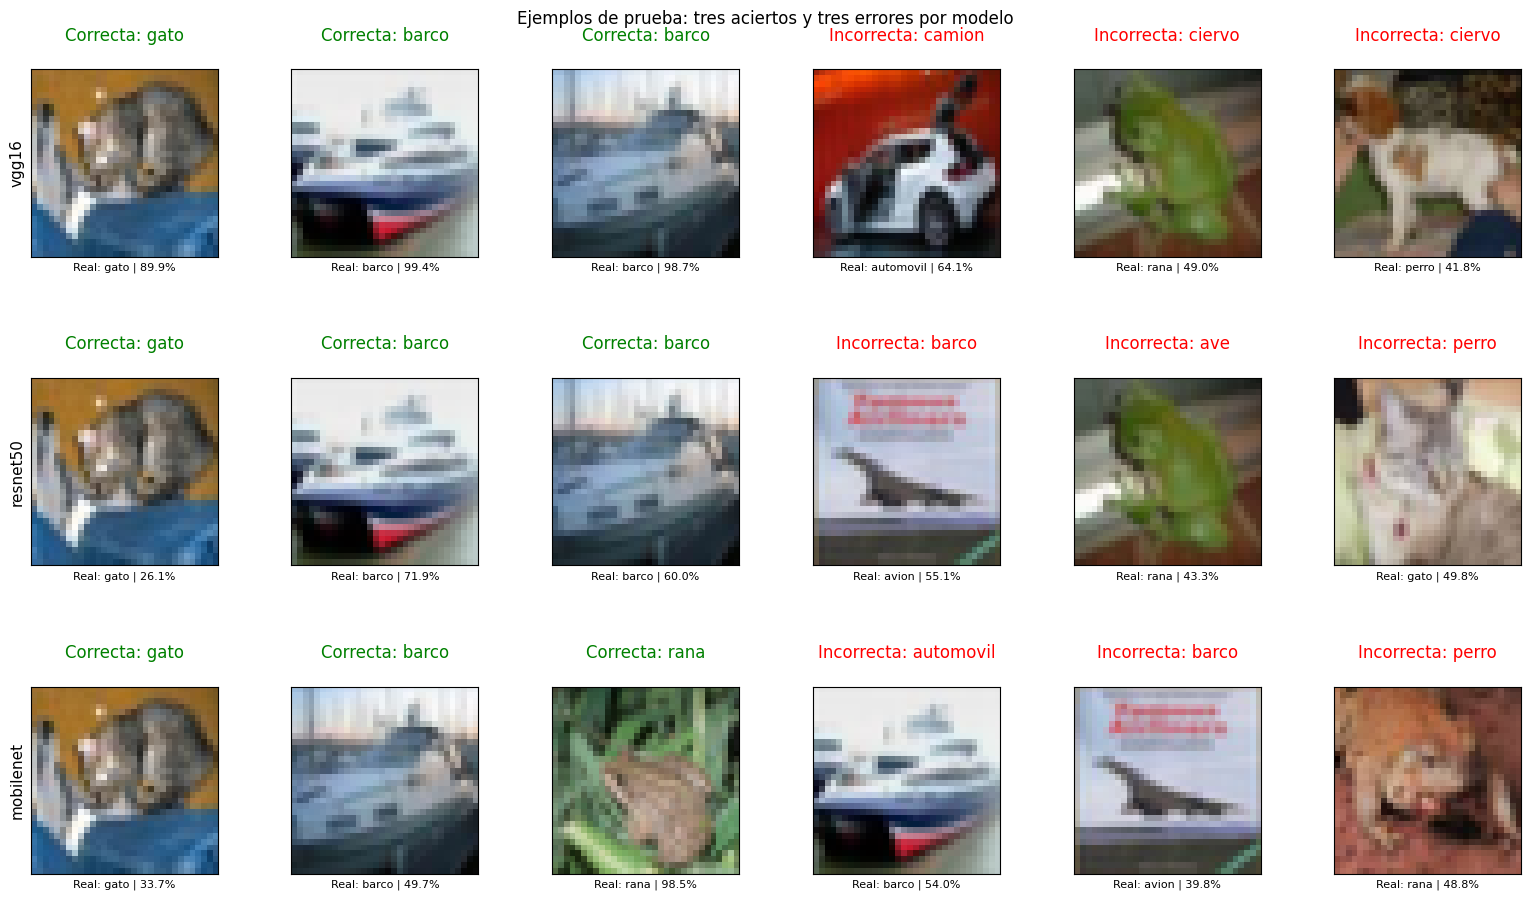

In [ ]:
""" Ejemplos visuales de predicciones correctas e incorrectas para cada arquitectura entrenada. """

nombres_clases = [
    "avion", "automovil", "ave", "gato", "ciervo",
    "perro", "rana", "caballo", "barco", "camion"
]

arquitecturas = ["vgg16", "resnet50", "mobilenet"]
y_real = y_test.reshape(-1)
figura, ejes = plt.subplots(3, 6, figsize=(16, 9))

for fila, arquitectura in enumerate(arquitecturas):
    ruta = Path("artefactos") / "modelos" / f"{arquitectura}_cifar10.keras"
    if not ruta.exists():
        for eje in ejes[fila]:
            eje.axis("off")
        continue

    modelo = keras.models.load_model(ruta)
    test_ds = preparar_datos(x_test, y_test, arquitectura, batch_size=32)
    probabilidades = modelo.predict(test_ds, verbose=0)
    y_pred = probabilidades.argmax(axis=1)

    correctos = np.flatnonzero(y_pred == y_real)
    incorrectos = np.flatnonzero(y_pred != y_real)
    indices = np.concatenate((correctos[:3], incorrectos[:3]))

    for columna, indice in enumerate(indices):
        eje = ejes[fila, columna]
        eje.imshow(x_test[indice])
        acierto = y_pred[indice] == y_real[indice]
        estado = "Correcta" if acierto else "Incorrecta"
        confianza = probabilidades[indice, y_pred[indice]]
        eje.set_title(
            f"{estado}: {nombres_clases[y_pred[indice]]}\n",
            color="green" if acierto else "red"
        )
        eje.set_xlabel(
            f"Real: {nombres_clases[y_real[indice]]} | {confianza:.1%}",
            fontsize=8
        )
        eje.set_xticks([])
        eje.set_yticks([])

    ejes[fila, 0].set_ylabel(arquitectura, fontsize=11)

figura.suptitle("Ejemplos de prueba: tres aciertos y tres errores por modelo")
figura.tight_layout()
figura.subplots_adjust(hspace=0.65)

plt.show()


# Conclusiones:

Los modelos vgg16 y resnet son CNN didácticas personalizadas entrenadas desde cero con el mismo protocolo, mobilenetv2 es un modelo de referencia con transfer-learning.

El modelo vgg16 es el que obtuvo la mejor puntuación en la metrica accuracy en los datos de validación, el segundo es mobilenet y el tercero resnet50. El modelo vgg16 no tiene una diferencia significativa para indicar sobre-ajuste sobre su mejor resultado (en el intervalo de epocas ejecutado) en la metrica accuracy sobre los datos de entrenamiento y validación, sin embargo el modelo resnet50 muestra este comportamiento entre los datos de entrenamiento y validación, indicando sobre ajuste. Tambien se encuentra en la metrica de perdida (Loss). Una posible exploracion para el modelo ResNet50 es configurar un intervalo de 0.4 - 0.5 en las capas Dropout, esta medida con el objetivo de aumentar la generalización del modelo. Tambien es posible aumentar la regularización. 

En consideración de un resultado de 61.4% en los datos de prueba del modelo ResNet, aun considerando, el sobre-ajuste del modelo es real. A razón de que el conjunto de prediccion no representa a todas las clases en proporciones similares, por lo que se puede decir que el conjunto de prueba tiene una semejanza mayor al conjunto de entrenamiento que el conjunto de validación. Lo anterior escrito como una posible hipotesis.

ResNet fue el unico modelo en ser detenido en su entrenamiento, porque earlystopping detecto que no generalizaba mejor en tres epocas, ya que su perdida en sobre-ajuste aumento en este intervalo. Se puede observar en la grafica.

En la comparación de los ejemplos visuales de tres errores y tres aciertos por modelo se puede observar como el modelo vgg16 tiene una confianza muy por encima sobre las etiquetas correctas en comparacion a los otros dos. 

Los resultados de mobilenet usando transferlearning son por que los pesos de Imagenet fueron diseñados para extraer caracteristicas de imagenes de mayor tamaño, las capas finales son relativamente pequeñas en comparacion al total incluyendo los pesos de la base congelada, los datos de cifar son pequeños favoreciendo una cnn pequeña entrenada directamente en el dominio de CIFAR. 

En resumén los tres modelos pueden cambiar su rendimiento segun los datos que aborden, los metodos e hiperparametros que se apliquen y las estrategias paralelas que se configuren (transferlearning). En este caso por el rendimiento inicial me decantaria por el modelo vgg16, sin embargo considerando que el modelo didactico no es el resultado del modelo VGG16 de keras, el que podria tener resultados similares o no. Los modelos didacticos en este notebook funcionaron como aprendizaje de las capas que componen e diferencian a cada modelo.

Como trabajo futuro, se podría incorporar una matriz de confusión y métricas por clase para estudiar las confusiones específicas de cada arquitectura. Esto aportaría una comprensión más detallada del rendimiento y apoyar decisiones para optimización.